In [1]:
%%time
#%load_ext autoreload
#%autoreload 2

CPU times: user 9 μs, sys: 2 μs, total: 11 μs
Wall time: 20 μs


In [2]:
%%time

import os
import numpy as np

from matplotlib import pyplot as plt
from matplotlib.collections import LineCollection
import matplotlib.patches as patches
from matplotlib_scalebar.scalebar import ScaleBar

CPU times: user 6.42 s, sys: 49.2 ms, total: 6.47 s
Wall time: 540 ms


In [3]:
%%time
import skeliner as sk

CPU times: user 7.46 s, sys: 569 ms, total: 8.03 s
Wall time: 12.2 s


In [4]:
%%time
import sys

sys.path.append("../utils")

import data_io

CPU times: user 281 ms, sys: 73.1 ms, total: 354 ms
Wall time: 392 ms


# setup

In [5]:
%%time
cm = 1/2.54  # centimeters in inches
plt.style.use('paper.mplstyle')

CPU times: user 2.17 ms, sys: 11 μs, total: 2.18 ms
Wall time: 1.89 ms


In [6]:
%%time
### manually choose cells for example plot ###
example_cells = {
"A17": "720575940555793382",
"nNOS-1": "720575940562504921" ,
"A2" : "720575940562476215" ,
"Other": "720575940556857319"}

cmap = { "RBC" : "#0C7C59",
         "A2": "#134D7C",
         "A17":  "#32A9DE",
         "nNOS-1": "#B1DEF2",
         "Other":"#1D74B9" }

CPU times: user 10 μs, sys: 1e+03 ns, total: 11 μs
Wall time: 16.7 μs


# load data

In [7]:
%%time
config = data_io.get_data_config()
skel_dir = config.get("skel_dir", None)

CPU times: user 3.07 ms, sys: 13 μs, total: 3.08 ms
Wall time: 2.84 ms


In [8]:
%%time
assert os.path.isdir(skel_dir), skel_dir

CPU times: user 57 μs, sys: 0 ns, total: 57 μs
Wall time: 207 μs


In [9]:
%%time

skel_files = {'A17': f'{skel_dir}/{example_cells['A17']}.swc',
              'A2': f'{skel_dir}/{example_cells['A2']}.swc',
              'nNOS-1': f'{skel_dir}/{example_cells['nNOS-1']}.swc',
              'Other': f'{skel_dir}/{example_cells['Other']}.swc'}

CPU times: user 11 μs, sys: 0 ns, total: 11 μs
Wall time: 19.8 μs


In [10]:
%%time
try:
    sys.path.append("../dev")
    from skel_sync import sync_skeletons
    sync_skeletons(example_cells.values(), skel_dir, target_ext='.swc')
except ImportError:
    pass  # dev-only helper, not present outside this machine; swc-examples.zip should already cover this

CPU times: user 0 ns, sys: 1.44 ms, total: 1.44 ms
Wall time: 996 μs


In [11]:
%%time
skel_files

CPU times: user 7 μs, sys: 1 μs, total: 8 μs
Wall time: 15.5 μs


{'A17': '/gpfs01/berens/data/data/Eyewire2/database-exports/manuscript/swc_2026-09-16-15h/720575940555793382.swc',
 'A2': '/gpfs01/berens/data/data/Eyewire2/database-exports/manuscript/swc_2026-09-16-15h/720575940562476215.swc',
 'nNOS-1': '/gpfs01/berens/data/data/Eyewire2/database-exports/manuscript/swc_2026-09-16-15h/720575940562504921.swc',
 'Other': '/gpfs01/berens/data/data/Eyewire2/database-exports/manuscript/swc_2026-09-16-15h/720575940556857319.swc'}

# figure

In [12]:
%%time
version_out = config.get("version", None)
fig_dir = f'../figures/connectivity/v{version_out}'   # saved the figure into the folder of the latest general version for completeness. 
os.makedirs(fig_dir, exist_ok=True)

CPU times: user 280 μs, sys: 0 ns, total: 280 μs
Wall time: 261 μs


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


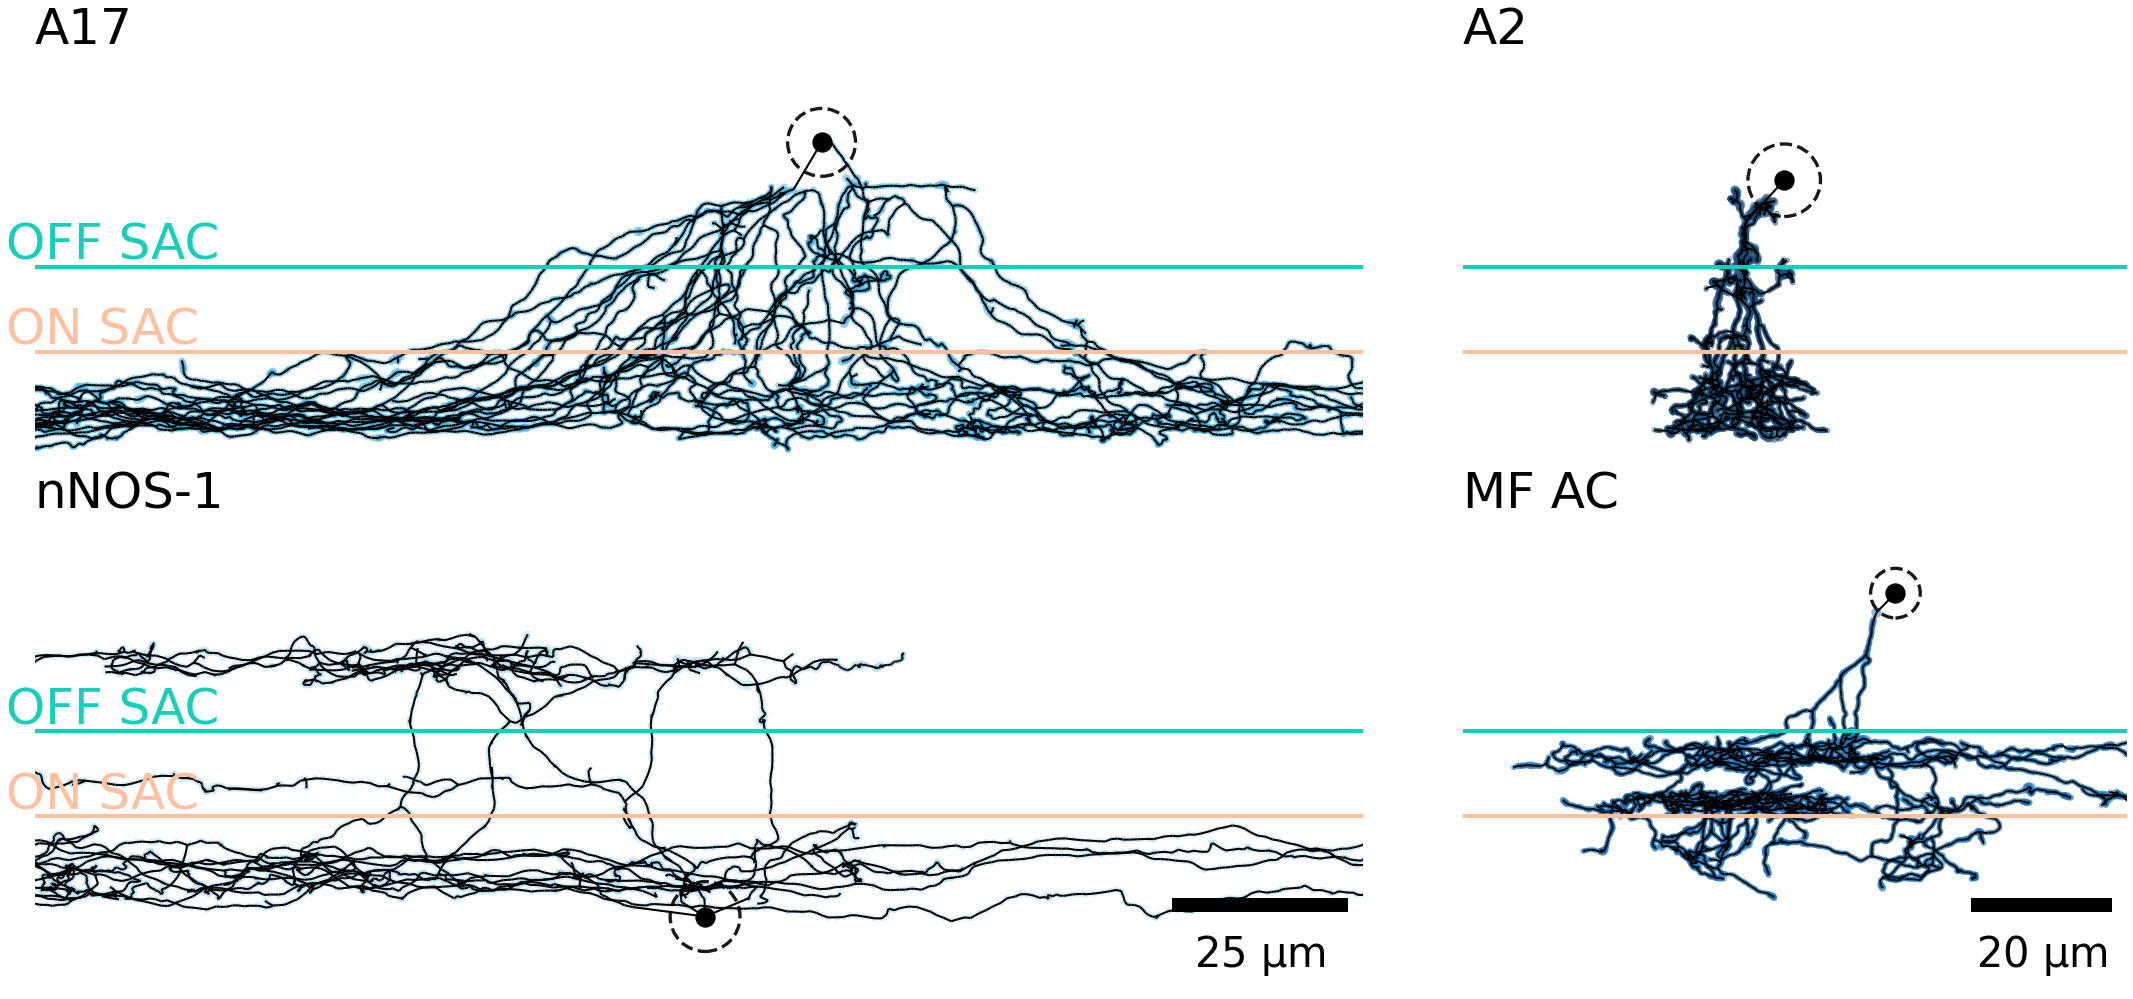

CPU times: user 3.62 s, sys: 117 ms, total: 3.74 s
Wall time: 3.99 s


In [13]:
%%time
ix = 0  # x-imension to plot (x-axis)
iy = 2  # y dimension to plot (z-axis)

on_sac_pos = 0.0
off_sac_pos = 12.0

on_sac_color = "#FFC09F"
off_sac_color = "#17CFB9"


fig = plt.figure(figsize=(9, 4))

fig.subplots_adjust(wspace=0.1, hspace = 0.01)
gs = fig.add_gridspec(
    2, 2,
    width_ratios=[2, 1],
    height_ratios=[1, 1]
)

axes_spec = [gs[0, 0], gs[1, 0], gs[0, 1], gs[1, 1]]

ylim = (-25, 40)
xlims = [(500, 900), (400, 800), (600, 800), (600, 800)]


# create first axis explicitly (shared y-axis reference)
ax0 = fig.add_subplot(axes_spec[0], frameon=False)
# ax0.set_rasterized(True)
# ax0.set_aspect("equal", adjustable="datalim")

for i, ct in enumerate(example_cells.keys()):

    segid = example_cells[ct]
    col = cmap[ct]

    skel_file = skel_files[ct]
    # mesh_file = f"{path_meshes}/{segid}.obj"

    if skel_file.endswith(".swc"):
        skel = sk.io.load_swc(skel_file)
    else:
        skel = sk.io.load_npz(skel_file)

    # mesh = sk.io.load_mesh(mesh_file)

    if i == 0:
        ax = ax0
    else:
        ax = fig.add_subplot(
            axes_spec[i],
            sharey=ax0,
            frameon=False
        )
   
    ax.set_xlim(xlims[i])
    ax.set_ylim(ylim)

    # 2d skeleton nodes
    v = sk.plot.vis2d._project(skel.nodes, ix,iy)
    
    radius_metric = skel.recommend_radius()[0]
    rr = skel.radii[radius_metric] 
    sizes, _ppd = sk.plot.vis2d._radii_to_sizes(rr, ax)

    ax.scatter(v[1:,0], v[1:,1], s = sizes[1:],
               facecolors = 'none', edgecolors = col, alpha = 0.5, zorder = -2000)


    # edges
    seg_start = v[skel.edges[:,0]]
    seg_end = v[skel.edges[:,1]]
    segments = np.stack((seg_start, seg_end), axis=1)

    lc = LineCollection(
        segments.tolist(),
        colors='k',
        linewidths=0.5,
        alpha=1,
        zorder = -1000
    )
    ax.add_collection(lc)

    
    # soma
    c_xy = sk.plot.vis2d._project(skel.nodes[[0]], ix, iy).ravel()
    ax.scatter(*c_xy, color= 'k', s=15, zorder=3)

    soma_circle = patches.Circle(
        c_xy,
        skel.soma.equiv_radius * 1.0,
        facecolor="none",
        edgecolor='k',
        linewidth=0.8,
        linestyle="--",
        alpha=0.9,
    )
    ax.add_patch(soma_circle)

    # reference lines
    ax.axhline(on_sac_pos, color = on_sac_color)
    ax.axhline(off_sac_pos, color= off_sac_color)

    if i == 0:  # bottom-left panel
        ax.text(602,1,'ON SAC', color = on_sac_color,fontsize = 12)
        ax.text(602,13,'OFF SAC', color = off_sac_color,fontsize = 12)

    if i == 1:  # bottom-left panel
        ax.text(502,1,'ON SAC', color = on_sac_color,fontsize = 12)
        ax.text(502,13,'OFF SAC', color = off_sac_color,fontsize = 12)

    # add scalebar to one panel only
    if i == 1 or i == 3:  # bottom-left panel
        scalebar = ScaleBar(
            dx=1e-3,          # matches scale argument above
            units="mm",
            length_fraction=0.25,
            height_fraction=0.03,
            loc = 'lower right',
            # bbox_to_anchor = (-20, 500),
            frameon=False)
        ax.add_artist(scalebar)

    ax.set_rasterization_zorder(0)
    ax.set_aspect('equal', adjustable = 'datalim')

    if ct == "Other":
        ct = "MF AC"
    if ct == "A1":
        ct = "nNOS-1 AC"
    ax.set_title(ct, loc="left", fontsize = 12)
    ax.set_axis_off()
    ax.set_xlim(xlims[i])
    ax.set_ylim(ylim)


plt.show()

fig.savefig(f'{fig_dir}/fig8__E_rbcexamples.svg',dpi = 300)

In [14]:
from watermark import watermark

print(watermark())

Last updated: 2026-11-13T17:56:21.429639+01:00

Python implementation: CPython
Python version       : 3.13.3
IPython version      : 9.13.0

Compiler    : Clang 20.1.0 
OS          : Linux
Release     : 5.14.0-687.10.1.el9_8.0.1.x86_64
Machine     : x86_64
Processor   : x86_64
CPU cores   : 48
Architecture: 64bit

